In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
df = pd.read_csv(r"C:\Users\vicky\OneDrive\Desktop\ejercricio nuevo\archive\amz_uk_processed_data.csv")
df.head()

,asin,title,imgUrl,productURL,stars,reviews,price,isBestSeller,boughtInLastMonth,categoryName
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/71C3lbbeLs...,https://www.amazon.co.uk/dp/B09B96TG33,4.7,15308,21.99,False,0,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",https://m.media-amazon.com/images/I/61c5rSxwP0...,https://www.amazon.co.uk/dp/B01HTH3C8S,4.7,98099,23.99,True,0,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/61j3SEUjMJ...,https://www.amazon.co.uk/dp/B09B8YWXDF,4.7,15308,21.99,False,0,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",https://m.media-amazon.com/images/I/71yf6yTNWS...,https://www.amazon.co.uk/dp/B09B8T5VGV,4.7,7205,31.99,False,0,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,https://m.media-amazon.com/images/I/613dEoF9-r...,https://www.amazon.co.uk/dp/B09WX6QD65,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab.head()

KeyError: 'category'

In [4]:
df.columns

Index(['asin', 'title', 'imgUrl', 'productURL', 'stars', 'reviews', 'price',
       'isBestSeller', 'boughtInLastMonth', 'categoryName'],
      dtype='object')

In [5]:
crosstab = pd.crosstab(df['categoryName'], df['isBestSeller'])
crosstab.head()

isBestSeller,False,True
categoryName,,
3D Printers,247,1
3D Printing & Scanning,4020,2
Abrasive & Finishing Products,245,5
Action Cameras,1014,0
Adapters,248,3


In [6]:
best_seller_ratio = crosstab[True] / (crosstab[True] + crosstab[False])
best_seller_ratio.sort_values(ascending=False).head(10)

categoryName
Health & Personal Care           0.058895
Grocery                          0.049865
Mobile Phone Accessories         0.039370
Power & Hand Tools               0.037645
Billiard, Snooker & Pool         0.032129
Pet Supplies                     0.030117
Home Brewing & Wine Making       0.028571
Arts & Crafts                    0.028318
Wind Instruments                 0.028000
Professional Medical Supplies    0.027344
dtype: float64

In [7]:
chi2, p, dof, expected = stats.chi2_contingency(crosstab)

print("Chi2:", chi2)
print("p-value:", p)

Chi2: 33019.04971964154
p-value: 0.0


In [8]:
import numpy as np

n = df.shape[0]
r, k = crosstab.shape

cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
cramers_v

np.float64(0.1218814906639688)

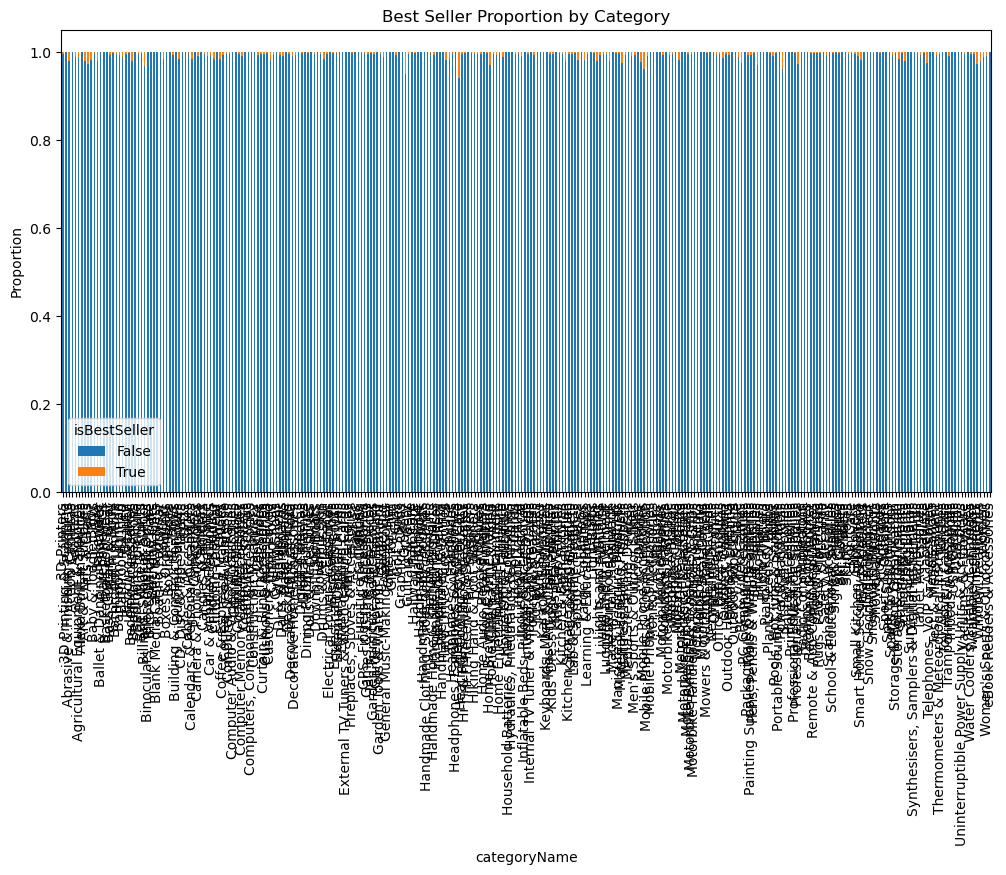

In [9]:
crosstab_norm = crosstab.div(crosstab.sum(axis=1), axis=0)

crosstab_norm.plot(kind='bar', stacked=True, figsize=(12,6))

plt.title("Best Seller Proportion by Category")
plt.ylabel("Proportion")
plt.xticks(rotation=90)
plt.legend(title="isBestSeller")
plt.show()

In [10]:
crosstab.head()

isBestSeller,False,True
categoryName,,
3D Printers,247,1
3D Printing & Scanning,4020,2
Abrasive & Finishing Products,245,5
Action Cameras,1014,0
Adapters,248,3


In [11]:
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 10)

crosstab.head()

isBestSeller,False,True
categoryName,,
3D Printers,247,1
3D Printing & Scanning,4020,2
Abrasive & Finishing Products,245,5
Action Cameras,1014,0
Adapters,248,3


In [12]:
crosstab = crosstab.sort_values(by=True, ascending=False)
crosstab.head()

isBestSeller,False,True
categoryName,,
Health & Personal Care,7750,485
Grocery,5964,313
Sports & Outdoors,825773,303
Pet Supplies,9146,284
Power & Hand Tools,6212,243


In [13]:
crosstab_norm = crosstab.div(crosstab.sum(axis=1), axis=0)
crosstab_norm.head()

isBestSeller,False,True
categoryName,,
Health & Personal Care,0.941105,0.058895
Grocery,0.950135,0.049865
Sports & Outdoors,0.999633,0.000367
Pet Supplies,0.969883,0.030117
Power & Hand Tools,0.962355,0.037645


In [14]:
top_categories = df['categoryName'].value_counts().head(10).index

crosstab_top = crosstab.loc[top_categories]
crosstab_top

isBestSeller,False,True
categoryName,,
Sports & Outdoors,825773,303
Skin Care,18697,58
Fragrances,18549,14
Make-up,18413,40
Manicure & Pedicure Products,17165,47
"Handmade Clothing, Shoes & Accessories",16699,8
Men,16237,147
Women,16101,183
Handmade Gifts,15759,31


In [15]:
df_clean = df.copy()

In [16]:
Q1 = df_clean['price'].quantile(0.25)
Q3 = df_clean['price'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_clean = df_clean[(df_clean['price'] >= lower) & (df_clean['price'] <= upper)]

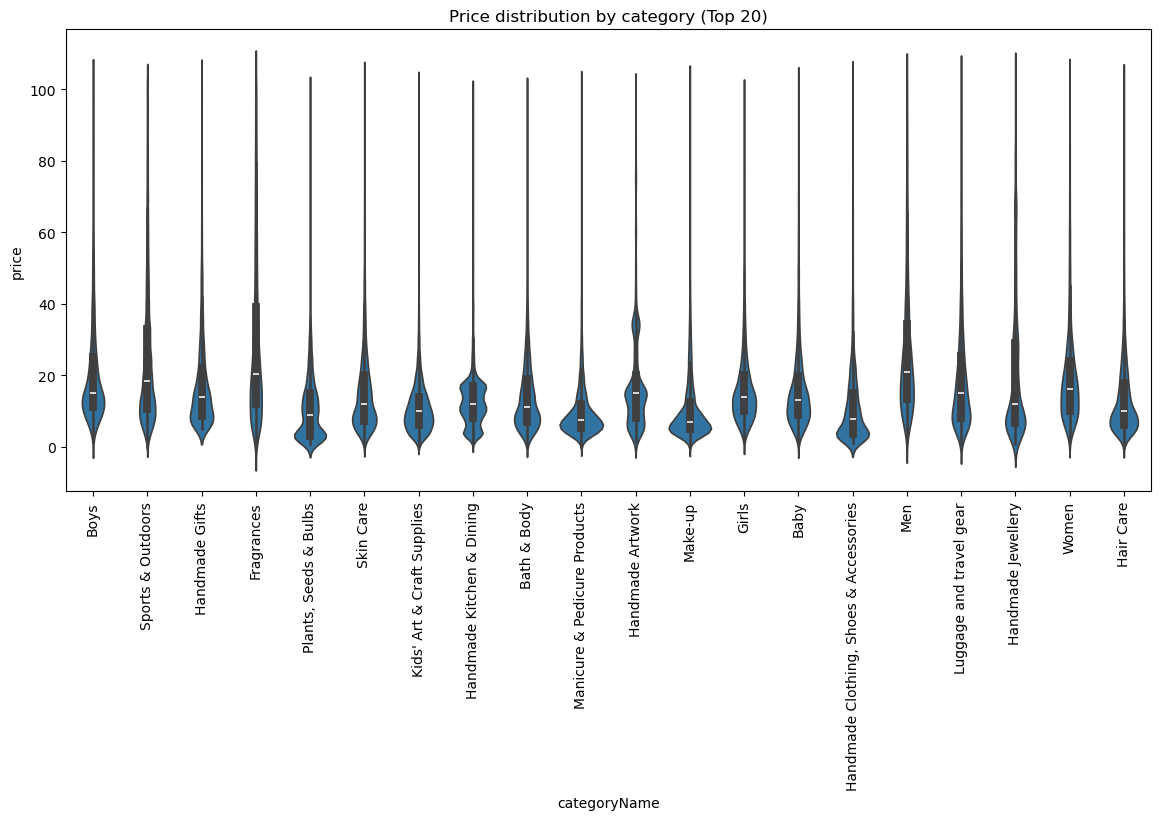

In [17]:
top20 = df_clean['categoryName'].value_counts().head(20).index
df_v = df_clean[df_clean['categoryName'].isin(top20)]

plt.figure(figsize=(14,6))
sns.violinplot(data=df_v, x='categoryName', y='price')
plt.xticks(rotation=90)
plt.title("Price distribution by category (Top 20)")
plt.show()

In [18]:
df_clean.groupby('categoryName')['price'].median().sort_values(ascending=False).head(10)

categoryName
Desktop PCs               75.000
Tablets                   70.140
Boxing Shoes              69.990
Graphics Cards            68.565
Motherboards              68.470
Digital Frames            65.625
Made in Italy Handmade    64.000
Ski Helmets               61.690
Home Bar Furniture        59.990
Home Office Furniture     59.210
Name: price, dtype: float64

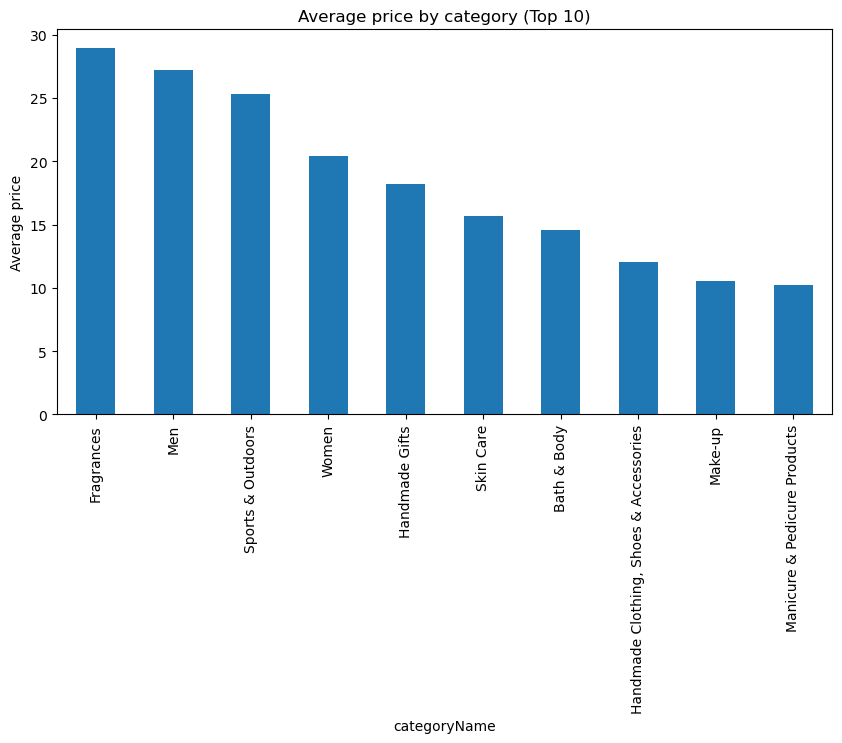

In [19]:
top10 = df_clean['categoryName'].value_counts().head(10).index
df_b = df_clean[df_clean['categoryName'].isin(top10)]

avg_price = df_b.groupby('categoryName')['price'].mean().sort_values(ascending=False)

avg_price.plot(kind='bar', figsize=(10,5))
plt.title("Average price by category (Top 10)")
plt.ylabel("Average price")
plt.xticks(rotation=90)
plt.show()

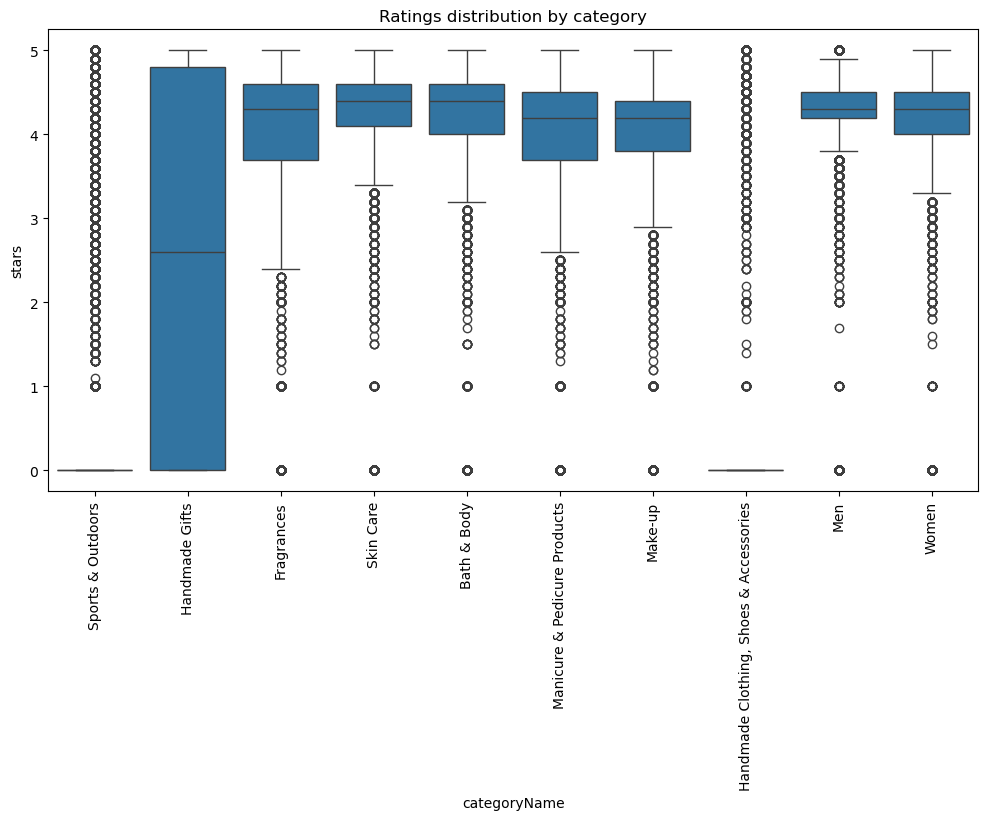

In [20]:
top10 = df_clean['categoryName'].value_counts().head(10).index
df_box = df_clean[df_clean['categoryName'].isin(top10)]

plt.figure(figsize=(12,6))
sns.boxplot(data=df_box, x='categoryName', y='stars')
plt.xticks(rotation=90)
plt.title("Ratings distribution by category")
plt.show()

In [21]:
df_clean[['price', 'stars']].corr()

,price,stars
price,1.000000,-0.066173
stars,-0.066173,1.000000


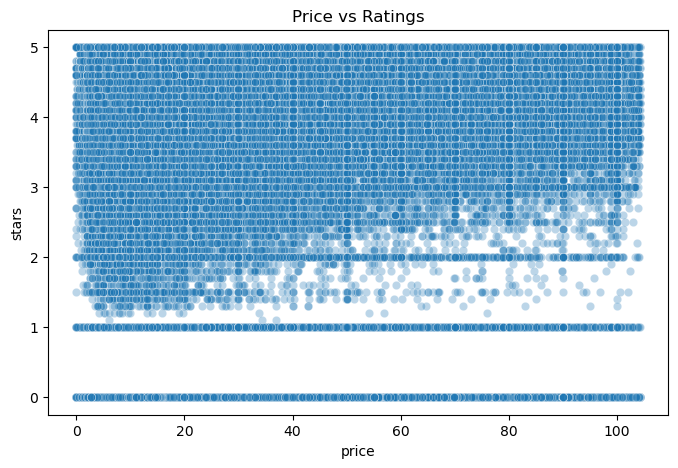

In [22]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_clean, x='price', y='stars', alpha=0.3)

plt.title("Price vs Ratings")
plt.show()

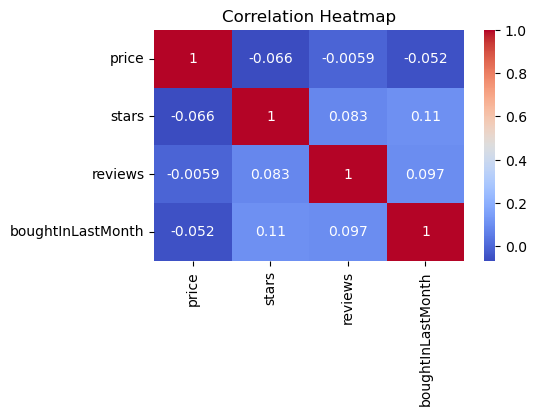

In [23]:
plt.figure(figsize=(5,3))
sns.heatmap(df_clean[['price', 'stars', 'reviews', 'boughtInLastMonth']].corr(), 
            annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

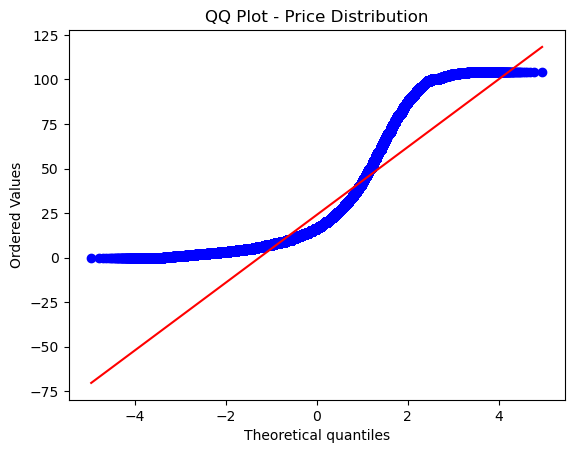

In [24]:
import scipy.stats as stats

stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title("QQ Plot - Price Distribution")
plt.show()